In [1]:
using SQLite
using StatsPlots; gr() # choose your favourite plotting backend
using PlotMGA
using DataFrames

## Data selection
### We first specify all data that we are interested in, alongside the data columns
### If the data is of a type that needs a different type of processing, we can define the processing as: 
```
function process_fn1(df)
    ...
end
function process_fn2(df)
    ...
end
process_spine_data(::Val{:new_type}) = process_fn1 ∘ process_fn2
```

In [2]:
#TODO: change to the directory where you hold your MGA results (a single directory per test case: no vs investable grid)
# Otherwise setup the db_paths manually
dir = "/home/s2860325/Downloads/ETHZ_FINAL"
# dir = "/home/s2860325/Downloads/ETHZ_FINAL_INV"
db_paths = ["$(dir)/$(method)/Output_$(method)_eps=0.$(eps).sqlite" for method in ["HSJ", "Fuzzy"] for eps in [1,3,6,9]]
total_costs = DataFrame()
storages_invested = DataFrame()
units_invested = DataFrame()
unit_flows = DataFrame()
node_states = DataFrame()
connections_invested = DataFrame()
for path in db_paths
    println(path)
    db = SQLite.DB(path)
    total_costs = vcat(total_costs, get_spine_parameter(db, :total_costs, 
        [:mga_iteration, :alternative, :total_value]), cols = :union)
    storages_invested = vcat(storages_invested, get_spine_parameter(db, :storages_invested, 
        [:mga_iteration, :alternative, :technology, :installation, :total_value, :technology_tag]), cols = :union)
    units_invested = vcat(units_invested, get_spine_parameter(db, :units_invested, 
        [:mga_iteration, :alternative, :technology, :installation, :total_value, :technology_tag]), cols = :union)
    unit_flows = vcat(unit_flows, get_spine_parameter(db, :unit_flow, 
        [:mga_iteration, :alternative, :technology, :installation, :destination, :total_value, :technology_tag]), cols = :union)
    node_states = vcat(node_states, get_spine_parameter(db, :node_state, 
        [:mga_iteration, :alternative, :technology, :total_value, :technology_tag]), cols = :union)
    connections_invested = vcat(connections_invested, get_spine_parameter(db, :connections_invested,
        [:mga_iteration, :alternative, :technology, :installation, :total_value, :technology_tag]), cols=:union)
    SQLite.close(db)
end

/home/s2860325/Downloads/ETHZ_FINAL_INV/HSJ/Output_HSJ_eps=0.1.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/HSJ/Output_HSJ_eps=0.3.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/HSJ/Output_HSJ_eps=0.6.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/HSJ/Output_HSJ_eps=0.9.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/Fuzzy/Output_Fuzzy_eps=0.1.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/Fuzzy/Output_Fuzzy_eps=0.3.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/Fuzzy/Output_Fuzzy_eps=0.6.sqlite
/home/s2860325/Downloads/ETHZ_FINAL_INV/Fuzzy/Output_Fuzzy_eps=0.9.sqlite


In [3]:
function process_tech_capacity(df)
    df.technology_tag  = df.details .|> first
    df = df[in.(df.alternative, Ref(["Base", "MGA-invest"])) ,:] # discuss
    df.capacity = df.value
    df
end
PlotMGA.process_spine_data(::Val{:unit_capacity}) = process_tech_capacity
PlotMGA.process_spine_data(::Val{:node_state_cap}) = process_tech_capacity
PlotMGA.process_spine_data(::Val{:connection_capacity}) = process_tech_capacity

In [4]:
#TODO database with technology data
input = "/home/s2860325/Downloads/System-MGA-invest(1).sqlite"
db = SQLite.DB(input)
unit_capacity = get_spine_parameter(db, :unit_capacity, [:capacity, :technology_tag])
node_capacity = get_spine_parameter(db, :node_state_cap, [:capacity, :technology_tag])
SQLite.close(db)

In [5]:
all_tags = units_invested.technology_tag |> unique
storage_tags = node_capacity.technology_tag |> unique
unit_tags = setdiff(all_tags, storage_tags)

unit_capacity = unit_capacity[in.(unit_capacity.technology_tag, Ref(unit_tags)), :]
all_capacities = vcat(unit_capacity, node_capacity)
units_invested = leftjoin(units_invested, all_capacities, on=:technology_tag)
units_invested.total_value = units_invested.capacity .* units_invested.total_value;
any(ismissing.(units_invested.capacity))

false

In [6]:
remove_district(technology) = split(technology, "_")[1]
units_invested.technology = units_invested.technology .|> remove_district
storages_invested.technology = storages_invested.technology .|> remove_district
unit_flows.technology = unit_flows.technology .|> remove_district;

In [7]:
rename_units = Dict(x=>x for x in unique(units_invested.technology))
rename_units["Wind Turbine 2 (onshore-3.3MW)"] = "Wind Turbine (onshore-3.3MW)"
units_invested.technology = units_invested.technology.|> x -> rename_units[x];

rename_units = Dict(x=>x for x in unique(unit_flows.technology))
rename_units["Wind Turbine 2 (onshore-3.3MW)"] = "Wind Turbine (onshore-3.3MW)"
unit_flows.technology = unit_flows.technology.|> x -> rename_units[x];

In [10]:
tech_total_investment = units_invested |> x -> groupby(x, :technology) |> x -> combine(x, :total_value => sum => :total_value)
used_tech = tech_total_investment.technology[tech_total_investment.total_value .> 0]
storages_invested = storages_invested[in.(storages_invested.technology, Ref(used_tech)), :]
units_invested = units_invested[in.(units_invested.technology, Ref(used_tech)), :]
# unit_flows = unit_flows[in.(unit_flows.technology, Ref(used_tech)), :]
unit_flows = unit_flows[contains.(unit_flows.destination, r"(Electricity|Space_Heating|Hydrogen)"), :]
node_states = node_states[in.(node_states.technology, Ref(used_tech)), :];

In [11]:
storages = unique(storages_invested.technology)

unit_flows = leftjoin(unit_flows, node_states, on=[:mga_iteration, :alternative, :technology_tag]; makeunique=true)
storage_idx = in.(unit_flows.technology, Ref(storages))
unit_flows.total_value[storage_idx] = unit_flows.total_value_1[storage_idx];

In [12]:
#TODO setup a path to an existing folder
picture_folder = "pics/" # a lot of pictures are generated, so its better to keep them in a folder

"pics/"

## Plotting the flow profiles
### We can plot how the profiles change in every MGA iteration.
### We define all of the commodity flow profile types, along with their properties, that we are inserested in plotting. The profiles are grouped, e.g., according to the commodity of the flow. The group can be defined:
```
[
    ProfileType(profile_name_1, df_filter_predicate_1),
    ProfileType(profile_name_2, df_filter_predicate_2),
    ...
]
```
### The plotting will be done over all of the combinations of the profiles types; in this case: electricity production, electricity storage, heat production, and heat storage
### Note that during plotting, we have to also specify the flow units (MWh or GWh)

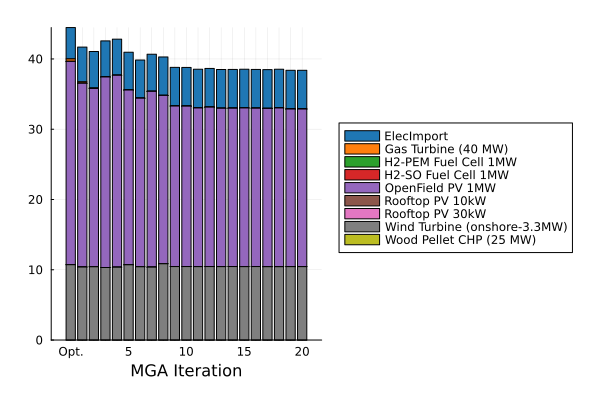

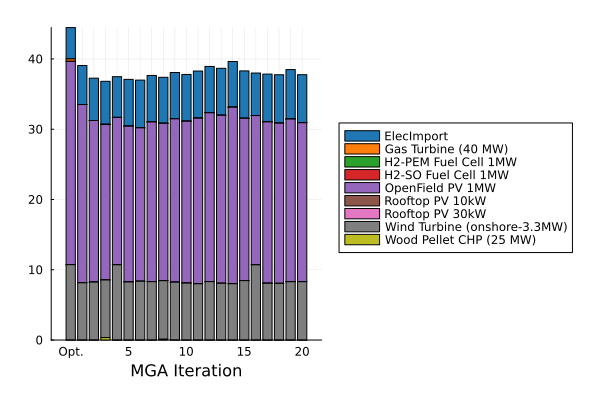

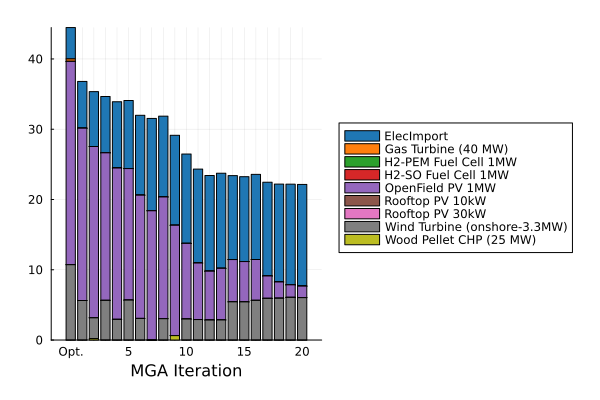

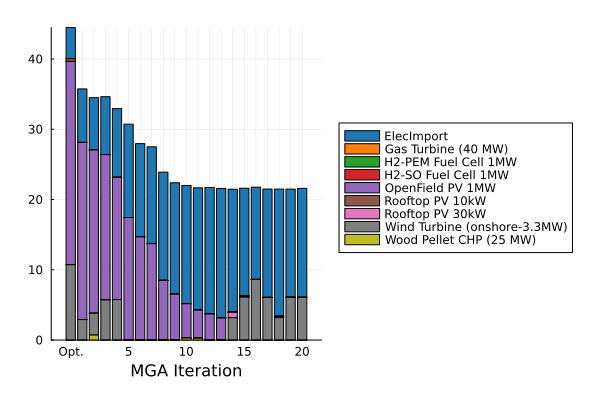

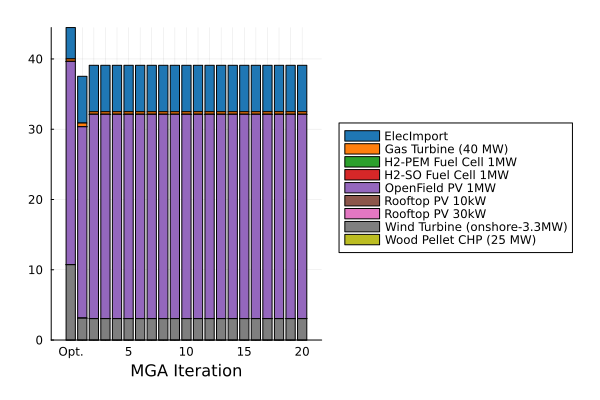

...

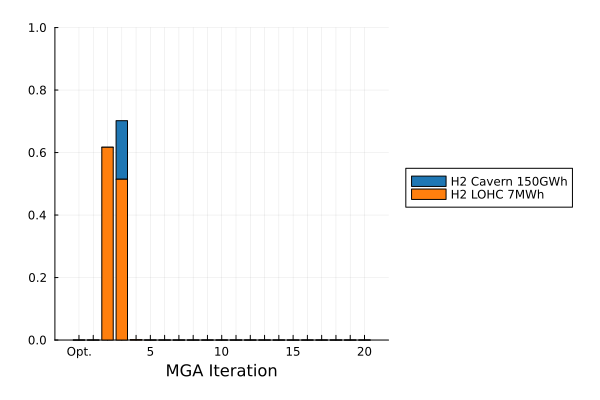

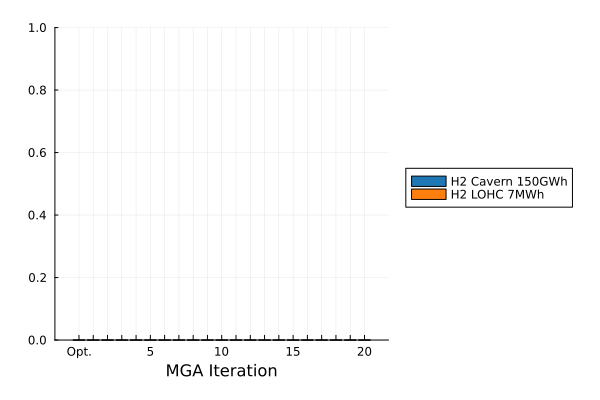

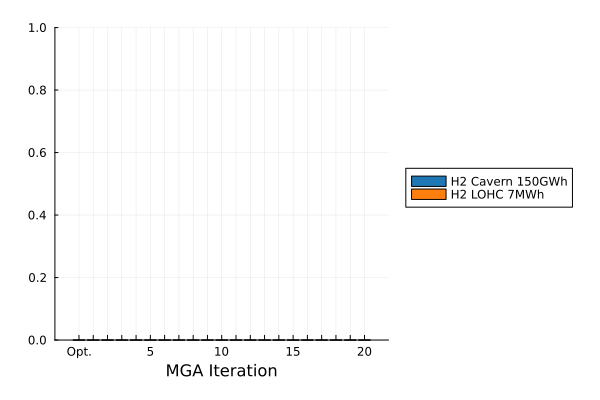

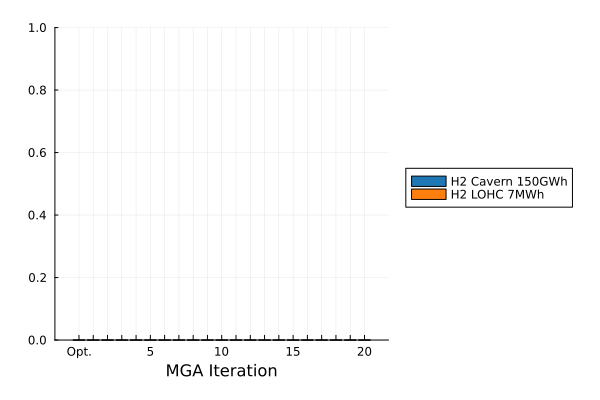

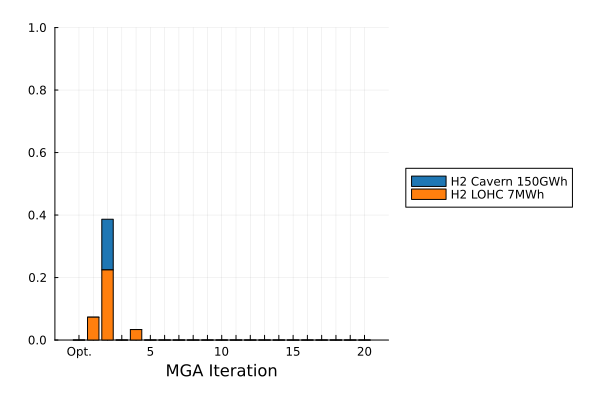

In [13]:
commodity_types = [
    ProfileType("Electricity", :destination=>ByRow(contains("Electricity"))),
    ProfileType("Heat", :destination=>ByRow(contains("Space_Heating"))),
    ProfileType("Hydrogen", :destination=>ByRow(contains("Hydrogen")))
]

production_types = [
    ProfileType("Production", :technology=>ByRow(!in(storages))),
    ProfileType("Storage", :technology=>ByRow(in(storages))),
]
sort!(unit_flows, :alternative)
plot_all_mga_profiles(
    unit_flows, PlotMGA.GWh, commodity_types, production_types,
    fig_prefix="$(picture_folder)mga_profile_for_"
)

## Plotting interactions between technologies, and their effects
### We can plot how the capacity of installed technology reacts with different technological installations.
### As the plotting is done over every alternative in database (e.g., used algorithm) we have to define markers to differentiate between them. We have to also define the marker for the optimal solution
### Here interactions are also plotted against the costs, but any df with effects will do (e.g, CO2 emmissions)

In [14]:
markers = Dict(
    "HSJ_eps=0.1" => :x,
    "HSJ_eps=0.3" => :x,	
    "HSJ_eps=0.6" => :x,	
    "HSJ_eps=0.9" => :x,	
    "Fuzzy_eps=0.1" => :utriangle,
    "Fuzzy_eps=0.3" => :rect,	
    "Fuzzy_eps=0.6" => :pentagon,	
    "Fuzzy_eps=0.9" => :hexagon,	
    "Optimal" => :circle
);

In [15]:
plot_technology_interactions(
    units_invested, total_costs, markers, 
    fig_prefix="$(picture_folder)technology_interactions_", display_plot=false
)

In [16]:
plot_technology_effects(
    units_invested, total_costs, markers; 
    fig_prefix="$(picture_folder)technology_effects_on_cost_", display_plot=false
)

In [ ]:
#TODO: run the code below only for the case with investable grids

In [17]:
db = SQLite.DB(input)
conn_capacity = get_spine_parameter(db, :connection_capacity, [:technology_tag, :capacity])
SQLite.close(db)
connections_invested = leftjoin(connections_invested, conn_capacity, on=:technology_tag)
connections_invested.total_value = connections_invested.capacity .* connections_invested.total_value;

In [18]:
total_connections = connections_invested |> x -> groupby(x, [:technology]) |> x -> combine(x, :total_value => sum => :total_value)
used_connections = total_connections[total_connections.total_value .> 0, :].technology |> unique

2-element Vector{String}:
 "District_Heating"
 "H2- MediumPressure pipe"

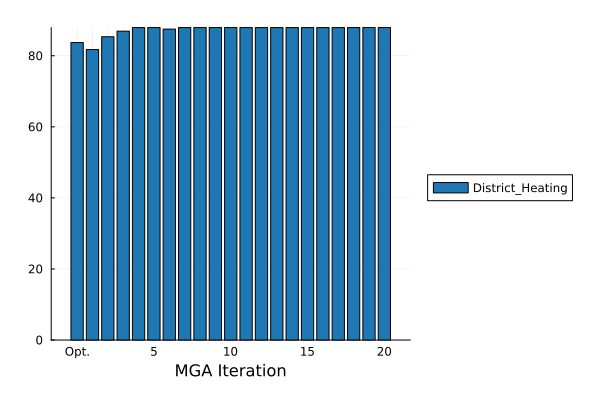

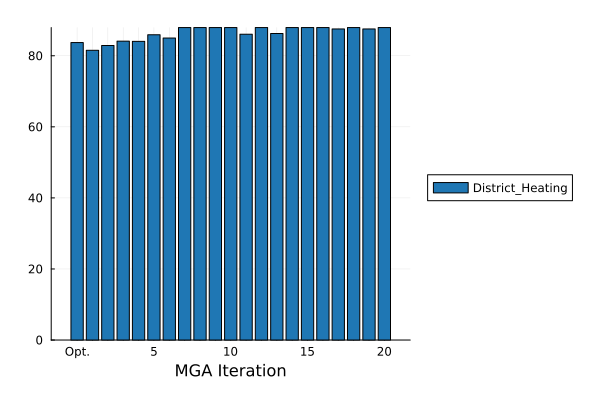

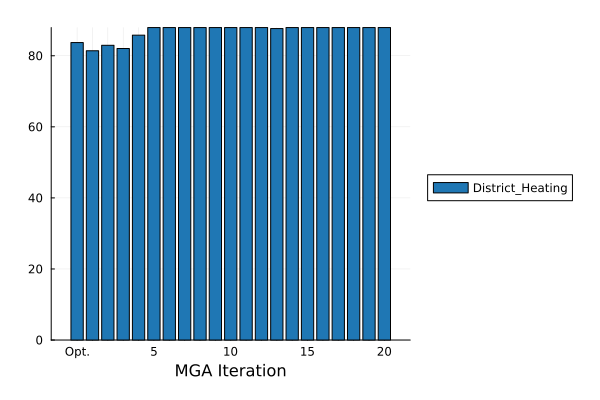

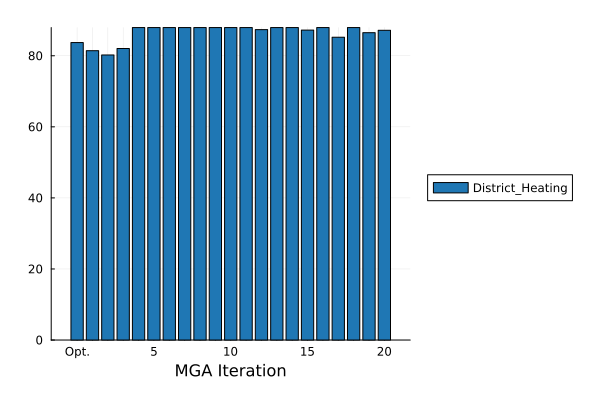

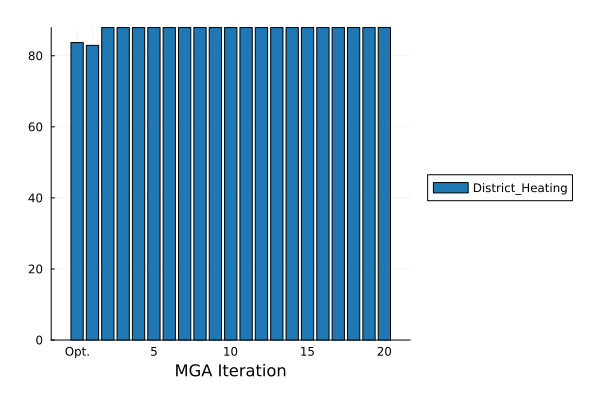

...

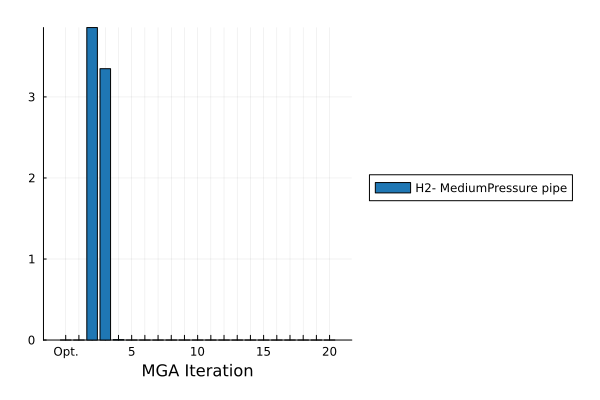

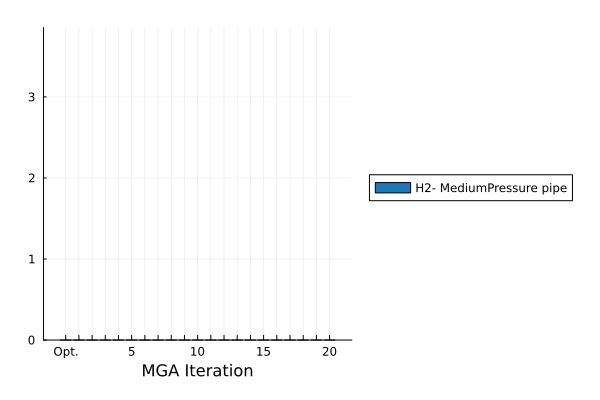

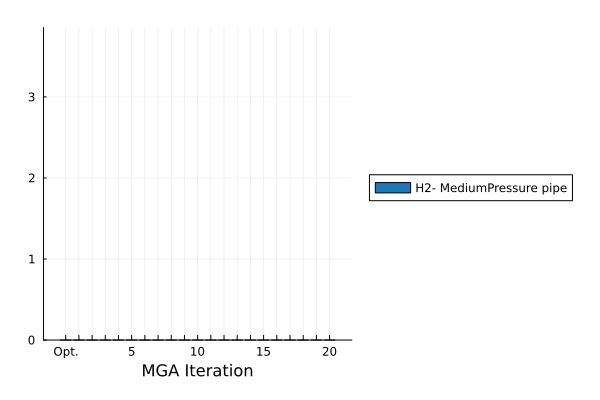

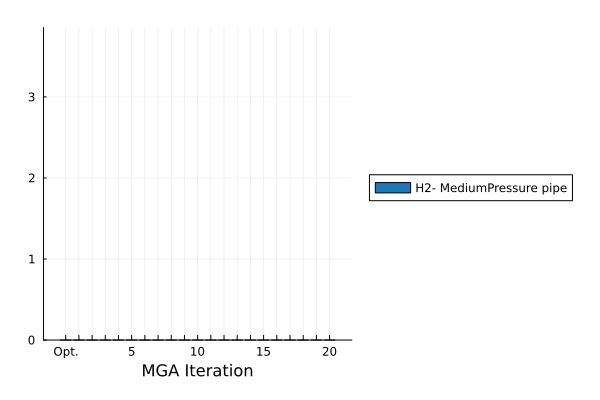

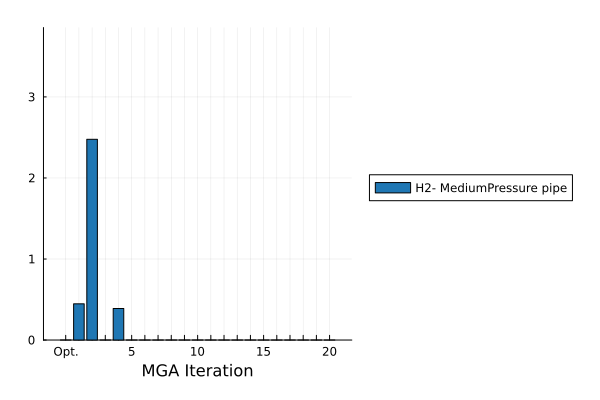

In [19]:
conn1 = [
    ProfileType("Heat", :technology=>ByRow(contains("Heating"))),
    ProfileType("H2", :technology=>ByRow(contains("H2")))
]

conn2 = [
    ProfileType("", :mga_iteration=>ByRow(x -> true)),
]

plot_all_mga_profiles(
    connections_invested, PlotMGA.MWh, conn1, conn2,
    fig_prefix=fig_prefix="$(picture_folder)connections_investment_"
)